# 02 Classification: Custom CNN and Transfer Learning

This notebook trains and compares two types of classification models for the mushroom dataset:

1. A custom CNN trained from scratch.
2. A transfer learning model based on a pretrained CNN backbone.


## 1. Imports and settings


All paths and training settings are defined in one place.


In [1]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight


SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

PROJECT_DIR = Path.cwd()
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "models"

TRAIN_CSV = PROCESSED_DIR / "train.csv"
VAL_CSV = PROCESSED_DIR / "val.csv"
TEST_CSV = PROCESSED_DIR / "test.csv"

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("Processed data directory:", PROCESSED_DIR)
print("Model directory:", MODEL_DIR)

for csv_path in [TRAIN_CSV, VAL_CSV, TEST_CSV]:
    if not csv_path.exists():
        raise FileNotFoundError(
            f"Missing file: {csv_path}\n"
            "Run 01_data_preparation_local_simple.ipynb first."
        )


TensorFlow version: 2.21.0
Processed data directory: c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-2\data\processed
Model directory: c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-2\models


## 2. Load prepared data

The previous notebook already sanitized the images and created the train, validation and test splits.

This notebook does not scan the raw image folders again. It only uses the prepared CSV files. This keeps the pipeline reproducible.


In [ ]:
train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

for df in [train_df, val_df, test_df]:
    df["absolute_path"] = df["path"].apply(lambda path: str(PROJECT_DIR / path))

label_table = (
    pd.concat([train_df, val_df, test_df])[["label", "label_id"]]
    .drop_duplicates()
    .sort_values("label_id")
)

label_names = label_table["label"].tolist()
num_classes = len(label_names)

print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Number of classes:", num_classes)

display(label_table)

Train images: 4697
Validation images: 1007
Test images: 1007
Number of classes: 9


,label,label_id
64,Mushroom Agaricus,0
2,Mushroom Amanita,1
14,Mushroom Boletus,2
4,Mushroom Cortinarius,3
0,Mushroom Entoloma,4
19,Mushroom Hygrocybe,5
1,Mushroom Lactarius,6
10,Mushroom Russula,7
9,Mushroom Suillus,8


## 3. Class imbalance

The data preparation notebook showed that the dataset is imbalanced. The largest class has much more images than the smallest class.

I use class weights during training. With class weights, mistakes on smaller classes receive more weight in the loss function.


In [16]:
train_class_distribution = train_df["label"].value_counts().sort_index()
display(train_class_distribution)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.sort(train_df["label_id"].unique()),
    y=train_df["label_id"].values
)

class_weights = {
    class_id: weight
    for class_id, weight in zip(np.sort(train_df["label_id"].unique()), class_weights_array)
}

class_weight_table = pd.DataFrame({
    "label_id": list(class_weights.keys()),
    "label": [label_names[class_id] for class_id in class_weights.keys()],
    "class_weight": list(class_weights.values())
})

display(class_weight_table)


label
Mushroom Agaricus        247
Mushroom Amanita         525
Mushroom Boletus         749
Mushroom Cortinarius     585
Mushroom Entoloma        255
Mushroom Hygrocybe       221
Mushroom Lactarius      1094
Mushroom Russula         803
Mushroom Suillus         218
Name: count, dtype: int64

,label_id,label,class_weight
0,0,Mushroom Agaricus,2.112910
1,1,Mushroom Amanita,0.994074
2,2,Mushroom Boletus,0.696781
3,3,Mushroom Cortinarius,0.892118
4,4,Mushroom Entoloma,2.046623
5,5,Mushroom Hygrocybe,2.361488
6,6,Mushroom Lactarius,0.477047
7,7,Mushroom Russula,0.649924
8,8,Mushroom Suillus,2.393986


## 4. TensorFlow datasets

The images are loaded from the prepared image paths in the CSV files.

The model receives images resized to `224 x 224`. Labels are integer class IDs, so the loss function will be sparse categorical cross-entropy.

Data augmentation is defined later inside the model. It is applied only during training by Keras.


In [17]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label


def make_dataset(df, shuffle=False):
    paths = df["absolute_path"].values
    labels = df["label_id"].values

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(df), seed=SEED)

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

for image_batch, label_batch in train_ds.take(1):
    print("Image batch shape:", image_batch.shape)
    print("Label batch shape:", label_batch.shape)


Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)


## 5. Metrics and callbacks

This is a single-label multi-class classification problem. Each image belongs to exactly one mushroom class.

The models use:

- `sparse_categorical_crossentropy` as the loss function;
- accuracy during training;
- classification report and confusion matrix during final evaluation.

I use three callbacks:

- `EarlyStopping`: stops training when validation loss no longer improves;
- `ReduceLROnPlateau`: lowers the learning rate when validation loss stops improving;
- `ModelCheckpoint`: saves the best model based on validation loss.

This avoids manually stopping the final model too early. The model is allowed to train for many epochs, but the best epoch is selected automatically.


In [19]:
def make_callbacks(model_path):
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=6,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.3,
            patience=3,
            min_lr=1e-6
        ),
        keras.callbacks.ModelCheckpoint(
            filepath=model_path,
            monitor="val_loss",
            save_best_only=True
        )
    ]


data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
], name="data_augmentation")


## 6. Helper functions for evaluation

Only the final selected models are evaluated in detail.

The notebook shows only:

- learning curves for the final model;
- classification report;
- confusion matrix;
- final test loss and test accuracy.


In [21]:
def plot_learning_curves(history, title):
    plt.figure(figsize=(8, 4))
    plt.plot(history.history["accuracy"], label="train accuracy")
    plt.plot(history.history["val_accuracy"], label="validation accuracy")
    plt.title(title + " accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.plot(history.history["loss"], label="train loss")
    plt.plot(history.history["val_loss"], label="validation loss")
    plt.title(title + " loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()


def evaluate_model(model, dataset, df, title):
    test_loss, test_accuracy = model.evaluate(dataset, verbose=0)

    probabilities = model.predict(dataset, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    true_labels = df["label_id"].values

    print(title)
    print("Test loss:", round(test_loss, 4))
    print("Test accuracy:", round(test_accuracy, 4))
    print()
    print(classification_report(true_labels, predictions, target_names=label_names))

    matrix = confusion_matrix(true_labels, predictions)
    display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=label_names)
    display.plot(xticks_rotation=90)
    plt.title(title + " confusion matrix")
    plt.tight_layout()
    plt.show()

    return test_loss, test_accuracy


# Part A: Custom CNN

## 7. Candidate custom CNN architectures

I compare three small CNN architectures:

1. `small_cnn`: lower capacity baseline.
2. `wider_cnn`: more filters, same depth.
3. `deeper_cnn`: one extra convolution block and a larger dense layer.

This comparison checks two common ways to increase model capacity:

- making the network wider;
- making the network deeper.

The final dense layer size is also part of this comparison. I compare `128` and `256` units.


In [22]:
def build_custom_cnn(conv_blocks, base_filters, dense_units, dropout_rate):
    inputs = keras.Input(shape=IMG_SIZE + (3,))

    x = data_augmentation(inputs)
    x = layers.Rescaling(1.0 / 255.0)(x)

    for block_index in range(conv_blocks):
        filters = base_filters * (2 ** block_index)

        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation="relu")(x)
    x = layers.Dropout(dropout_rate)(x)

    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


custom_candidates = {
    "small_cnn": {
        "conv_blocks": 3,
        "base_filters": 32,
        "dense_units": 128,
        "dropout_rate": 0.30
    },
    "wider_cnn": {
        "conv_blocks": 3,
        "base_filters": 48,
        "dense_units": 128,
        "dropout_rate": 0.30
    },
    "deeper_cnn": {
        "conv_blocks": 4,
        "base_filters": 32,
        "dense_units": 256,
        "dropout_rate": 0.40
    }
}


## 8. Quick custom CNN comparison

The candidate models are trained for a limited number of epochs. This stage is only used to choose a promising architecture.

The selected architecture will then be trained more fully with EarlyStopping.


In [24]:
custom_results = []

for model_name, parameters in custom_candidates.items():
    print("\nTraining candidate:", model_name)

    model = build_custom_cnn(**parameters)

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=10,
        class_weight=class_weights,
        callbacks=make_callbacks(MODEL_DIR / f"{model_name}.keras"),
        verbose=1
    )

    custom_results.append({
        "model": model_name,
        "best_val_loss": min(history.history["val_loss"]),
        "best_val_accuracy": max(history.history["val_accuracy"]),
        **parameters
    })

custom_results_df = pd.DataFrame(custom_results).sort_values("best_val_loss")
display(custom_results_df)

best_custom_row = custom_results_df.iloc[0]
best_custom_name = best_custom_row["model"]

print("Selected custom CNN:", best_custom_name)



Training candidate: small_cnn
Epoch 1/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 39s 170ms/step - accuracy: 0.1710 - loss: 2.1543 - val_accuracy: 0.1599 - val_loss: 2.9573 - learning_rate: 0.0010
Epoch 2/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 33s 162ms/step - accuracy: 0.2322 - loss: 1.9166 - val_accuracy: 0.1152 - val_loss: 3.5658 - learning_rate: 0.0010
Epoch 3/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 33s 163ms/step - accuracy: 0.2492 - loss: 1.9086 - val_accuracy: 0.1589 - val_loss: 2.5454 - learning_rate: 0.0010
Epoch 4/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 32s 163ms/step - accuracy: 0.2846 - loss: 1.7795 - val_accuracy: 0.2443 - val_loss: 1.9546 - learning_rate: 0.0010
Epoch 5/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 32s 162ms/step - accuracy: 0.3001 - loss: 1.7742 - val_accuracy: 0.2254 - val_loss: 2.1146 - learning_rate: 0.0010
Epoch 6/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 32s 162ms/step - accuracy: 0.3241 - loss: 1.7227 - val_accuracy: 0.2413 - val_loss: 2.0511 - learning_rate: 0.0010
Epoch 7/10
147/147 ━━━━━━━━━━━━━━━━━━━━

,model,best_val_loss,best_val_accuracy,conv_blocks,base_filters,dense_units,dropout_rate
0,small_cnn,1.717150,0.358491,3,32,128,0.3
2,deeper_cnn,1.756149,0.385303,4,32,256,0.4
1,wider_cnn,1.883957,0.301887,3,48,128,0.3


Selected custom CNN: small_cnn


### Custom CNN selection

The selected custom CNN is `small_cnn`.

It was selected because it achieved the lowest validation loss during the candidate comparison: `1.7172`.

The `deeper_cnn` model had the highest validation accuracy: `0.3853`, while `small_cnn` achieved `0.3585`. However, I selected the model based on validation loss because validation loss is more sensitive to the confidence of the predictions and is also the metric monitored by the callbacks.

This result suggests that the smaller model generalized slightly better in terms of validation loss. The deeper model had more capacity, but it did not achieve the best validation loss in this candidate comparison.


## 9. Final custom CNN training

`small_cnn` is trained for up to 50 epochs.

This does not mean the model must use all 50 epochs. EarlyStopping will stop training when validation loss no longer improves and restore the best weights.


In [25]:
best_custom_parameters = {
    "conv_blocks": int(best_custom_row["conv_blocks"]),
    "base_filters": int(best_custom_row["base_filters"]),
    "dense_units": int(best_custom_row["dense_units"]),
    "dropout_rate": float(best_custom_row["dropout_rate"])
}

custom_model = build_custom_cnn(**best_custom_parameters)

custom_history = custom_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    class_weight=class_weights,
    callbacks=make_callbacks(MODEL_DIR / "best_custom_model.keras"),
    verbose=1
)


Epoch 1/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 40s 169ms/step - accuracy: 0.1900 - loss: 2.1413 - val_accuracy: 0.1142 - val_loss: 3.0065 - learning_rate: 0.0010
Epoch 2/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 33s 163ms/step - accuracy: 0.2461 - loss: 1.9324 - val_accuracy: 0.1599 - val_loss: 3.8159 - learning_rate: 0.0010
Epoch 3/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 33s 163ms/step - accuracy: 0.2959 - loss: 1.8259 - val_accuracy: 0.2423 - val_loss: 2.0754 - learning_rate: 0.0010
Epoch 4/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 33s 163ms/step - accuracy: 0.3110 - loss: 1.7612 - val_accuracy: 0.2959 - val_loss: 1.7928 - learning_rate: 0.0010
Epoch 5/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 33s 163ms/step - accuracy: 0.3081 - loss: 1.7411 - val_accuracy: 0.2294 - val_loss: 2.1065 - learning_rate: 0.0010
Epoch 6/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 32s 162ms/step - accuracy: 0.3243 - loss: 1.7013 - val_accuracy: 0.3227 - val_loss: 1.8897 - learning_rate: 0.0010
Epoch 7/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 33s 162ms/step - accuracy: 0.3

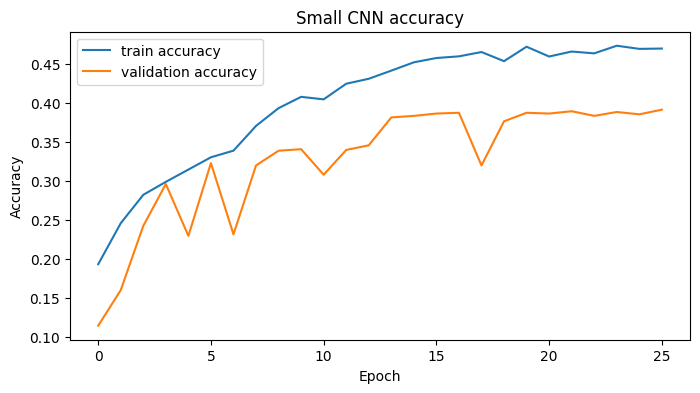

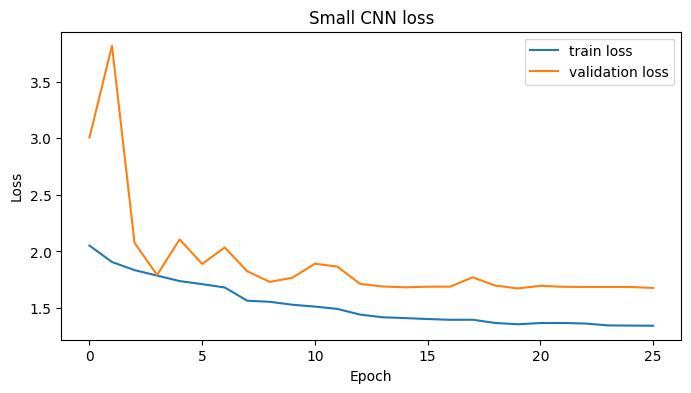

Small CNN
Test loss: 1.7231
Test accuracy: 0.3525

                      precision    recall  f1-score   support

   Mushroom Agaricus       0.20      0.57      0.30        53
    Mushroom Amanita       0.34      0.59      0.43       112
    Mushroom Boletus       0.73      0.49      0.59       161
Mushroom Cortinarius       0.37      0.34      0.35       125
   Mushroom Entoloma       0.29      0.18      0.22        55
  Mushroom Hygrocybe       0.55      0.50      0.52        48
  Mushroom Lactarius       0.55      0.17      0.26       235
    Mushroom Russula       0.59      0.20      0.30       172
    Mushroom Suillus       0.13      0.63      0.21        46

            accuracy                           0.35      1007
           macro avg       0.41      0.41      0.35      1007
        weighted avg       0.49      0.35      0.36      1007



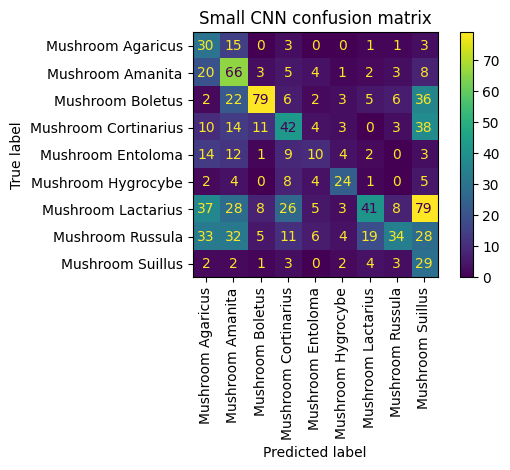

In [40]:
plot_learning_curves(custom_history, "Small CNN")

custom_model = keras.models.load_model(MODEL_DIR / "best_custom_model.keras")
custom_test_loss, custom_test_accuracy = evaluate_model(
    custom_model,
    test_ds,
    test_df,
    "Small CNN"
)


### Small CNN evaluation

The final `small_cnn` model achieved a test accuracy of `0.3525` and a test loss of `1.7231`.

The learning curves show that the model learned some patterns, but the performance remained limited.

The validation loss decreased at the beginning and then became almost flat, so EarlyStopping was useful. The classification report also confirms weak performance, with a weighted average F1-score of only `0.36`.

The confusion matrix shows many off-diagonal errors. The model often confuses visually similar classes and predicts several classes incorrectly as `Mushroom Suillus`, `Mushroom Amanita`, or `Mushroom Cortinarius`.

Overall, `small_cnn` is a useful baseline, but it is not good enough as the final model. Transfer learning is expected to perform better because it uses pretrained visual features.

# Part B: Transfer Learning

## 10. Candidate pretrained backbones

For transfer learning, I compare three common pretrained CNN backbones:

1. `MobileNetV2`: lightweight and suitable for limited hardware.
2. `VGG16`: older but very common baseline architecture.
3. `ResNet50`: common residual network baseline.

The backbone is frozen during the candidate comparison, and only the classification head is trained. This keeps the comparison simple and feasible on my hardware.


In [33]:
def build_transfer_model(backbone_name, dense_units=128, dropout_rate=0.30):
    inputs = keras.Input(shape=IMG_SIZE + (3,))

    x = data_augmentation(inputs)

    if backbone_name == "MobileNetV2":
        preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input
        base_model = tf.keras.applications.MobileNetV2(
            include_top=False,
            weights="imagenet",
            input_shape=IMG_SIZE + (3,)
        )

    elif backbone_name == "VGG16":
        preprocess_input = tf.keras.applications.vgg16.preprocess_input
        base_model = tf.keras.applications.VGG16(
            include_top=False,
            weights="imagenet",
            input_shape=IMG_SIZE + (3,)
        )

    elif backbone_name == "ResNet50":
        preprocess_input = tf.keras.applications.resnet50.preprocess_input
        base_model = tf.keras.applications.ResNet50(
            include_top=False,
            weights="imagenet",
            input_shape=IMG_SIZE + (3,)
        )

    else:
        raise ValueError("Unknown backbone: " + backbone_name)

    base_model.trainable = False

    x = preprocess_input(x)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation="relu")(x)
    x = layers.Dropout(dropout_rate)(x)

    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


## 11. Quick transfer learning comparison

Each backbone is trained with the same simple classification head. This makes the comparison mainly about the pretrained feature extractor, not about changing many settings at once.


In [34]:
transfer_candidates = ["MobileNetV2", "VGG16", "ResNet50"]
transfer_results = []

for backbone_name in transfer_candidates:
    print("\nTraining backbone:", backbone_name)

    model = build_transfer_model(
        backbone_name=backbone_name,
        dense_units=128,
        dropout_rate=0.30
    )

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=8,
        class_weight=class_weights,
        callbacks=make_callbacks(MODEL_DIR / f"{backbone_name}.keras"),
        verbose=1
    )

    transfer_results.append({
        "backbone": backbone_name,
        "best_val_loss": min(history.history["val_loss"]),
        "best_val_accuracy": max(history.history["val_accuracy"]),
        "dense_units": 128,
        "dropout_rate": 0.30
    })

transfer_results_df = pd.DataFrame(transfer_results).sort_values("best_val_loss")
display(transfer_results_df)

best_backbone = transfer_results_df.iloc[0]["backbone"]

print("Selected transfer backbone:", best_backbone)



Training backbone: MobileNetV2
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
147/147 ━━━━━━━━━━━━━━━━━━━━ 25s 76ms/step - accuracy: 0.3298 - loss: 1.8132 - val_accuracy: 0.6326 - val_loss: 1.0832 - learning_rate: 0.0010
Epoch 2/8
147/147 ━━━━━━━━━━━━━━━━━━━━ 18s 59ms/step - accuracy: 0.5824 - loss: 1.1005 - val_accuracy: 0.6584 - val_loss: 0.9696 - learning_rate: 0.0010
Epoch 3/8
147/147 ━━━━━━━━━━━━━━━━━━━━ 17s 59ms/step - accuracy: 0.6679 - loss: 0.8764 - val_accuracy: 0.6991 - val_loss: 0.8828 - learning_rate: 0.0010
Epoch 4/8
147/147 ━━━━━━━━━━━━━━━━━━━━ 17s 56ms/step - accuracy: 0.6834 - loss: 0.7725 - val_accuracy: 0.6783 - val_loss: 0.8871 - learning_rate: 0.0010
Epoch 5/8
147/147 ━━━━━━━━━━━━━━━━━━━━ 17s 60ms/step - accuracy: 0.7142 - loss: 0.7317 - val_accuracy: 0.6971 - val_loss: 0.8229 - learning_rate: 0.0010
Epoch 6/8
147/147 ━━━━━━━━━━━━━━━━━━━━ 17s 59ms/step - accuracy: 0.7352 - loss: 0.6597 - val_accuracy: 0.7170 - val_loss: 0.8111 - learning_rate: 0.0010
E

,backbone,best_val_loss,best_val_accuracy,dense_units,dropout_rate
2,ResNet50,0.696889,0.758689,128,0.3
0,MobileNetV2,0.808405,0.716981,128,0.3
1,VGG16,1.017126,0.681231,128,0.3


Selected transfer backbone: ResNet50


### Transfer learning selection

The selected transfer learning backbone is `ResNet50`.

It was selected because it achieved the lowest validation loss: `0.6969`. It also achieved the highest validation accuracy: `0.7587`.

This makes `ResNet50` the strongest candidate among the tested backbones.


## 12. Final transfer learning training

`ResNet50` is trained for up to 50 epochs.

The pretrained backbone remains frozen. The classification head learns how to map pretrained visual features to the mushroom classes.


In [35]:
transfer_model = build_transfer_model(
    backbone_name=best_backbone,
    dense_units=128,
    dropout_rate=0.30
)

transfer_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    class_weight=class_weights,
    callbacks=make_callbacks(MODEL_DIR / "best_transfer_model.keras"),
    verbose=1
)


Epoch 1/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 35s 123ms/step - accuracy: 0.3711 - loss: 1.7236 - val_accuracy: 0.6534 - val_loss: 1.0088 - learning_rate: 0.0010
Epoch 2/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 24s 105ms/step - accuracy: 0.6117 - loss: 1.0401 - val_accuracy: 0.6951 - val_loss: 0.8998 - learning_rate: 0.0010
Epoch 3/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 23s 97ms/step - accuracy: 0.6601 - loss: 0.8679 - val_accuracy: 0.6723 - val_loss: 0.9073 - learning_rate: 0.0010
Epoch 4/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 24s 105ms/step - accuracy: 0.7147 - loss: 0.7332 - val_accuracy: 0.7249 - val_loss: 0.8065 - learning_rate: 0.0010
Epoch 5/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 23s 98ms/step - accuracy: 0.7327 - loss: 0.6713 - val_accuracy: 0.7289 - val_loss: 0.8210 - learning_rate: 0.0010
Epoch 6/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 24s 106ms/step - accuracy: 0.7426 - loss: 0.6153 - val_accuracy: 0.7567 - val_loss: 0.6880 - learning_rate: 0.0010
Epoch 7/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 23s 99ms/step - accuracy: 0.7684

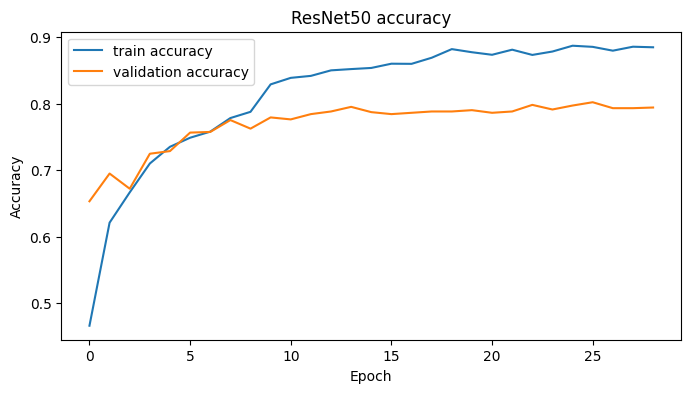

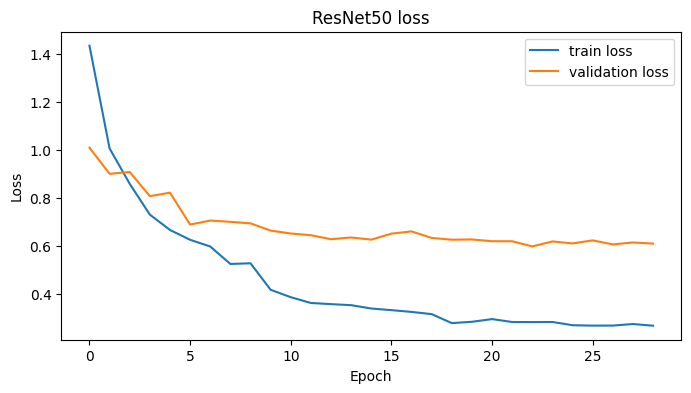

ResNet50
Test loss: 0.5781
Test accuracy: 0.8113

                      precision    recall  f1-score   support

   Mushroom Agaricus       0.85      0.74      0.79        53
    Mushroom Amanita       0.91      0.88      0.89       112
    Mushroom Boletus       0.89      0.91      0.90       161
Mushroom Cortinarius       0.77      0.76      0.77       125
   Mushroom Entoloma       0.72      0.71      0.72        55
  Mushroom Hygrocybe       0.81      0.81      0.81        48
  Mushroom Lactarius       0.83      0.75      0.79       235
    Mushroom Russula       0.76      0.87      0.81       172
    Mushroom Suillus       0.64      0.78      0.71        46

            accuracy                           0.81      1007
           macro avg       0.80      0.80      0.80      1007
        weighted avg       0.82      0.81      0.81      1007



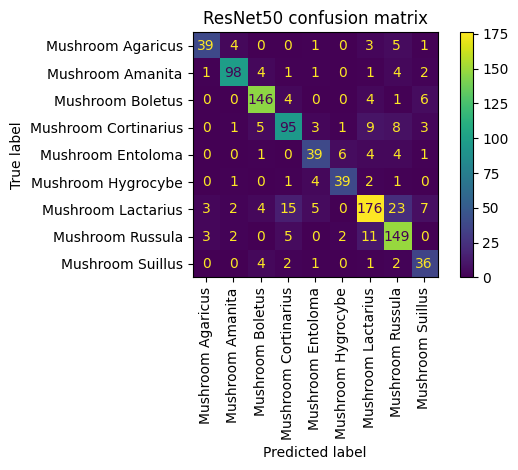

In [41]:
plot_learning_curves(transfer_history, "ResNet50")

transfer_model = keras.models.load_model(MODEL_DIR / "best_transfer_model.keras")
transfer_test_loss, transfer_test_accuracy = evaluate_model(
    transfer_model,
    test_ds,
    test_df,
    "ResNet50"
)


### ResNet50 evaluation

The final `ResNet50` transfer learning model achieved a test accuracy of `0.8113` and a test loss of `0.5781`.

The validation loss decreased at the beginning and then became almost flat. EarlyStopping was useful because it selected the best checkpoint based on validation loss.

The classification report confirms the strong result, with a weighted average F1-score of `0.81`. The confusion matrix also shows that most predictions are on the diagonal, meaning most test images were classified correctly.

Most remaining errors happen between visually similar mushroom classes, especially around classes such as `Mushroom Lactarius`, `Mushroom Cortinarius`, `Mushroom Russula`, and `Mushroom Suillus`.

Overall, `ResNet50` is the best classification model in this notebook. It clearly outperforms the custom CNN and is selected as the final classification model.

# Part C: Final comparison

## 13. Custom CNN vs transfer learning

`ResNet50` and `small_cnn` are compared on the same test set.

The test set was not used for model selection. It is used only for final evaluation.


In [39]:
final_comparison = pd.DataFrame([
    {
        "model": "Small CNN",
        "test_loss": custom_test_loss,
        "test_accuracy": custom_test_accuracy
    },
    {
        "model": "ResNet50",
        "test_loss": transfer_test_loss,
        "test_accuracy": transfer_test_accuracy
    }
])

display(final_comparison)


,model,test_loss,test_accuracy
0,Small CNN,1.723059,0.352532
1,ResNet50,0.578054,0.811321


## 14. Final classification conclusion

The `Small CNN` achieved a test accuracy of `0.3525` and a test loss of `1.7231`.

The `ResNet50` transfer learning model achieved a test accuracy of `0.8113` and a test loss of `0.5781`.

The `ResNet50` model is the better classification model. It performs better on both test metrics: higher accuracy and lower loss.

This result is expected because `ResNet50` uses pretrained visual features, while the custom CNN has to learn all features from the mushroom dataset itself. The large difference in test accuracy shows that transfer learning is much more effective for this task.
